# Bayesian Nonparametrics: Dirichlet Process Mixtures for SPY Market Regimes

## Problem
How many market regimes are there in SPY daily data? A finite mixture needs K fixed in advance. A Dirichlet process (DP) prior lets the data decide how many components carry non-negligible weight, with an upper truncation level only for computation.

## Data
- **Source:** SPY (SPDR S&P 500 ETF) adjusted daily close, downloaded at run time from Yahoo Finance with `yfinance.download`, starting 2005-01-03 and running to the latest available trading day.
- **Features per day:** the daily log return $r_t$ and the log of the trailing 21-day annualised realised volatility $\log \mathrm{RV}_t$, both standardised. The first 21 days are dropped as warm-up.
- The numbers below depend on the download date, because the sample grows every trading day.

## Method
**Dirichlet process via stick-breaking.** With concentration $\alpha$,
$$v_k \sim \mathrm{Beta}(1,\alpha), \qquad \pi_k = v_k \prod_{j<k}(1-v_j), \qquad \sum_{k\ge1}\pi_k = 1 .$$
**Chinese restaurant process.** Customer $i$ joins an existing table $k$ with probability $\frac{n_k}{i-1+\alpha}$ or opens a new one with probability $\frac{\alpha}{i-1+\alpha}$. The expected number of tables after $n$ customers is $\sum_{i=0}^{n-1}\frac{\alpha}{\alpha+i}$, which grows like $\alpha\log n$.

**Mixture model.** $x_i \mid z_i=k \sim \mathcal N(\mu_k,\Sigma_k)$ and $z_i \sim \pi$. sklearn's `BayesianGaussianMixture(weight_concentration_prior_type='dirichlet_process')` fits a truncated version of this model with variational inference. Components that the data does not need collapse to near-zero weight. The result is compared with a fixed-K Gaussian mixture (`GaussianMixture`, EM) selected by BIC.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from sklearn.mixture import BayesianGaussianMixture, GaussianMixture
from sklearn.preprocessing import StandardScaler

SEED = 42
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=4, suppress=True)
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.5.3 | pandas 3.0.5


In [2]:
raw = yf.download("SPY", start="2005-01-01", auto_adjust=True, progress=False)
if isinstance(raw.columns, pd.MultiIndex):
    raw.columns = raw.columns.get_level_values(0)
px = raw["Close"].squeeze().dropna()
print(f"Trading days: {len(px)}  ({px.index[0].date()} to {px.index[-1].date()})")
print(px.tail(3).round(2).to_string())

Trading days: 5506  (2005-01-03 to 2026-11-19)
Date
2026-11-17    732.44
2026-11-18    730.20
2026-11-19    731.67


In [3]:
ret = np.log(px).diff()                        # daily log return
rv21 = ret.rolling(21).std() * np.sqrt(252)    # trailing 21-day annualised realised vol
df = pd.DataFrame({"price": px, "ret": ret, "log_rv": np.log(rv21)}).dropna()
scaler = StandardScaler()
X = scaler.fit_transform(df[["ret", "log_rv"]].values)
print("Observations after warm-up:", X.shape[0])
print(f"Annualised mean log return {df.ret.mean()*252:.3f}, annualised vol {df.ret.std()*np.sqrt(252):.3f}")

Observations after warm-up: 5485
Annualised mean log return 0.102, annualised vol 0.189


### Dirichlet-process mixture with K not fixed
The truncation level is set to 10, which is only an upper bound. The count of components with weight above 1% is what the data selects.

Fit time 32.1s | converged=True | iterations=650
Mixture weights (sorted): [0.2734 0.1919 0.1696 0.1602 0.1067 0.0406 0.0316 0.0258 0.0002 0.0001]
Components with weight > 0.01: 8 of truncation level 10


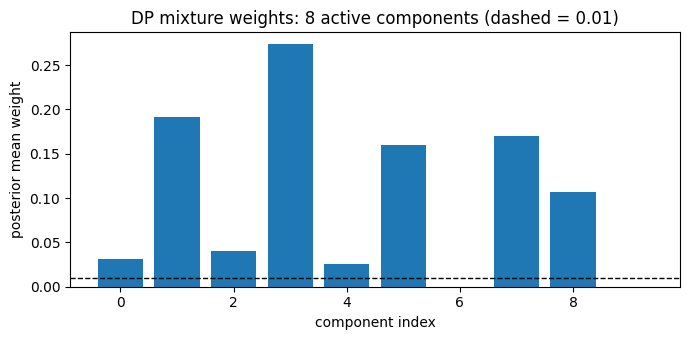

In [4]:
K_MAX = 10
ACTIVE_TOL = 0.01
t0 = time.time()
dp = BayesianGaussianMixture(
    n_components=K_MAX, covariance_type="full",
    weight_concentration_prior_type="dirichlet_process",
    weight_concentration_prior=1.0,
    max_iter=1000, n_init=3, random_state=SEED)
dp.fit(X)
w = dp.weights_
n_active = int((w > ACTIVE_TOL).sum())
print(f"Fit time {time.time()-t0:.1f}s | converged={dp.converged_} | iterations={dp.n_iter_}")
print("Mixture weights (sorted):", np.sort(w)[::-1].round(4))
print(f"Components with weight > {ACTIVE_TOL}: {n_active} of truncation level {K_MAX}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(range(K_MAX), w, color=["C0" if x > ACTIVE_TOL else "lightgrey" for x in w])
ax.axhline(ACTIVE_TOL, ls="--", c="k", lw=1)
ax.set_xlabel("component index"); ax.set_ylabel("posterior mean weight")
ax.set_title(f"DP mixture weights: {n_active} active components (dashed = {ACTIVE_TOL})")
plt.tight_layout(); plt.show()

### Sensitivity to the concentration parameter $\alpha$
A larger $\alpha$ favours more clusters under the prior, so the active count should rise with $\alpha$.

In [5]:
rows = []
for alpha in [0.1, 1.0, 10.0]:
    m = BayesianGaussianMixture(
        n_components=K_MAX, covariance_type="full",
        weight_concentration_prior_type="dirichlet_process",
        weight_concentration_prior=alpha, max_iter=1000, n_init=3,
        random_state=SEED).fit(X)
    rows.append((alpha, int((m.weights_ > ACTIVE_TOL).sum())))
sens = pd.DataFrame(rows, columns=["alpha", "active components"])
print(sens.to_string(index=False))

 alpha  active components
   0.1                  8
   1.0                  8
  10.0                  8


### Regimes over time and per-regime statistics
Each day is assigned to its most probable component. Regimes are numbered by realised volatility, with regime 0 the calmest.

 regime  days  share  ann_mean_return  ann_vol
      0  1934  0.353           -0.008    0.037
      1   792  0.144            1.962    0.047
      2   416  0.076           -2.395    0.062
      3    86  0.016            7.325    0.119
      4   109  0.020           -7.989    0.128
      5  1151  0.210            1.115    0.137
      6   870  0.159           -1.084    0.173
      7   127  0.023           -0.665    0.704


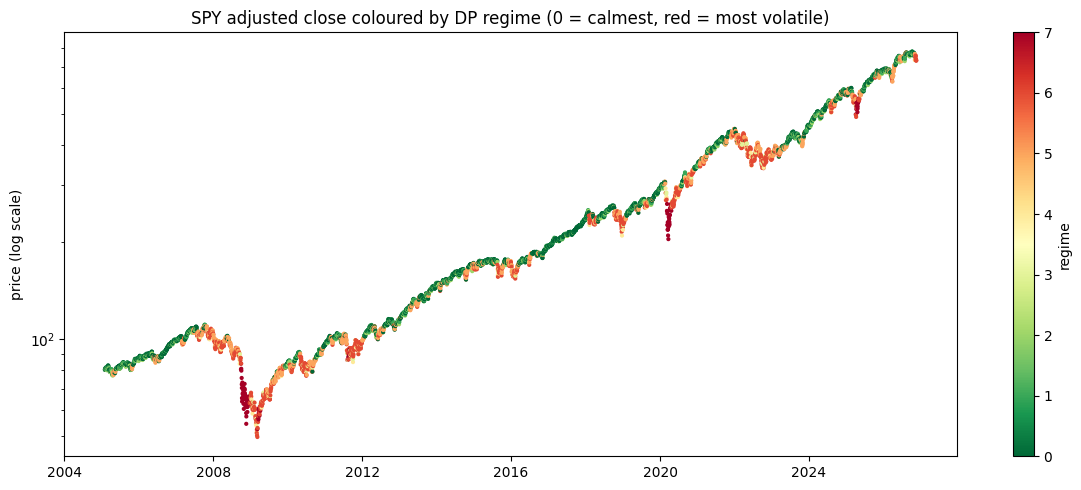

In [6]:
df["raw"] = dp.predict(X)
summ = df.groupby("raw").agg(days=("ret", "size"), mean_ret=("ret", "mean"),
                             std_ret=("ret", "std"))
summ = summ.sort_values("std_ret")
summ["regime"] = range(len(summ))
rank = dict(zip(summ.index, summ.regime))
df["regime"] = df["raw"].map(rank)

table = pd.DataFrame({
    "regime": summ.regime.values,
    "days": summ.days.values,
    "share": (summ.days / summ.days.sum()).values.round(3),
    "ann_mean_return": (summ.mean_ret * 252).values.round(3),
    "ann_vol": (summ.std_ret * np.sqrt(252)).values.round(3),
})
print(table.to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 5))
sc = ax.scatter(df.index, df.price, c=df.regime, cmap="RdYlGn_r", s=4)
ax.set_yscale("log")
ax.set_title("SPY adjusted close coloured by DP regime (0 = calmest, red = most volatile)")
ax.set_ylabel("price (log scale)")
cb = plt.colorbar(sc, ax=ax, ticks=range(len(table)))
cb.set_label("regime")
plt.tight_layout(); plt.show()

### From-scratch Chinese restaurant process and stick-breaking
These simulations do not use sklearn. They check the expected number of tables and show how the stick-breaking weights decay.

alpha= 0.5: E[tables] formula =   5.29, simulated mean of 5 runs =   5.60


alpha= 1.0: E[tables] formula =   9.19, simulated mean of 5 runs =   8.40


alpha= 5.0: E[tables] formula =  35.52, simulated mean of 5 runs =  35.40
alpha=1.0: mean weight of first 5 sticks [0.491 0.26  0.124 0.065 0.031]; sticks above 0.01 per draw: 4.6; min mass in 200 sticks: 1.000000
alpha=5.0: mean weight of first 5 sticks [0.165 0.142 0.112 0.094 0.082]; sticks above 0.01 per draw: 12.8; min mass in 200 sticks: 1.000000


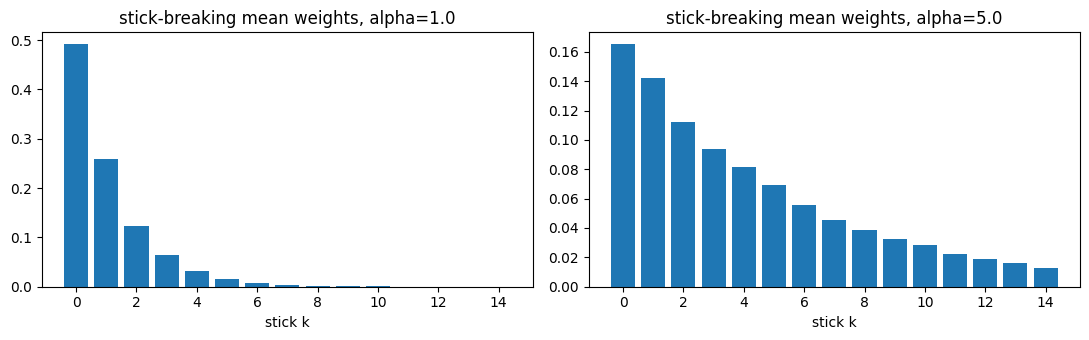

In [7]:
def crp_num_tables(n, alpha, rng):
    counts = []
    for i in range(n):
        p = np.array(counts + [alpha], dtype=float)
        k = rng.choice(len(p), p=p / p.sum())
        if k == len(counts):
            counts.append(1)
        else:
            counts[k] += 1
    return len(counts)

n = len(X)
for alpha in [0.5, 1.0, 5.0]:
    expected = sum(alpha / (alpha + i) for i in range(n))
    sims = [crp_num_tables(n, alpha, rng) for _ in range(5)]
    print(f"alpha={alpha:>4}: E[tables] formula = {expected:6.2f}, simulated mean of 5 runs = {np.mean(sims):6.2f}")

def stick_breaking(alpha, K, rng):
    v = rng.beta(1.0, alpha, size=K)
    remaining = np.concatenate([[1.0], np.cumprod(1 - v)[:-1]])
    return v * remaining

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, alpha in zip(axes, [1.0, 5.0]):
    W = np.array([stick_breaking(alpha, 200, rng) for _ in range(1000)])
    mean_w = W.mean(0)
    print(f"alpha={alpha}: mean weight of first 5 sticks {mean_w[:5].round(3)}; "
          f"sticks above {ACTIVE_TOL} per draw: {(W > ACTIVE_TOL).sum(1).mean():.1f}; "
          f"min mass in 200 sticks: {W.sum(1).min():.6f}")
    ax.bar(range(15), mean_w[:15])
    ax.set_title(f"stick-breaking mean weights, alpha={alpha}")
    ax.set_xlabel("stick k")
plt.tight_layout(); plt.show()

### Comparison with a fixed-K Gaussian mixture (BIC)
Each $K$ from 1 to 10 is fitted with EM and scored with BIC. The DP model's BIC is not computed here, because its variational objective is not a likelihood with a comparable parameter count. The BIC table therefore shows which fixed $K$ the criterion prefers.

1     31173.6
2     27997.5
3     27809.7
4     27388.1
5     27365.2
6     27356.6
7     27382.0
8     27405.7
9     27363.2
10    27471.2
BIC-optimal fixed K = 6; DP active components = 8


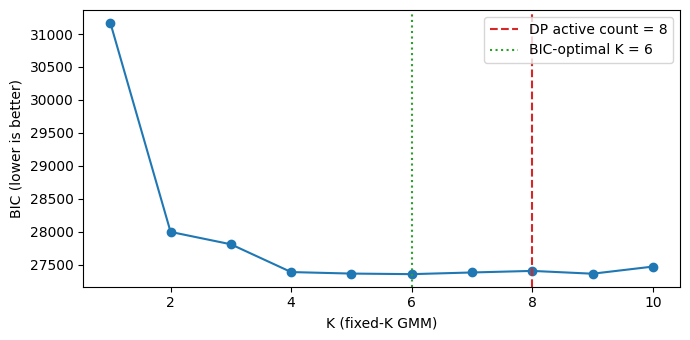

In [8]:
bic = {}
for k in range(1, K_MAX + 1):
    gm = GaussianMixture(n_components=k, covariance_type="full", n_init=3,
                         random_state=SEED).fit(X)
    bic[k] = gm.bic(X)
bic = pd.Series(bic, name="BIC")
k_star = int(bic.idxmin())
print(bic.round(1).to_string())
print(f"BIC-optimal fixed K = {k_star}; DP active components = {n_active}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(bic.index, bic.values, "o-")
ax.axvline(n_active, c="C3", ls="--", label=f"DP active count = {n_active}")
ax.axvline(k_star, c="C2", ls=":", label=f"BIC-optimal K = {k_star}")
ax.set_xlabel("K (fixed-K GMM)"); ax.set_ylabel("BIC (lower is better)")
ax.legend(); plt.tight_layout(); plt.show()

## Results

- Data: 5,506 SPY trading days (2005-01-03 to 2026-11-19); 5,485 observations after the 21-day warm-up. Annualised mean log return 0.102, annualised volatility 0.189.
- DP mixture (concentration 1.0, truncation level 10) converged in 650 iterations. **8 components** carry weight above 0.01. The two smallest weights are 0.0002 and 0.0001.
- The active count is 8 for concentration 0.1, 1.0 and 10.0, so it did not change across the tested range.
- Regime 0 (calmest): 1,934 days (35.3% of the sample), within-regime annualised volatility 3.7%. Regime 7 (most volatile): 127 days (2.3%), within-regime annualised volatility 70.4%.
- Regimes 3 and 4 are small (86 and 109 days). Their annualised mean returns (+7.325 and -7.989) extrapolate a few extreme days and are not meaningful as annual returns; the volatility columns are more reliable.
- Fixed-K GMM by BIC (K from 1 to 10) selects K = 6 (BIC 27,356.6). K = 9 (27,363.2) and K = 5 (27,365.2) are close, and the BIC curve is not monotone.
- The DP count (8) and the BIC-optimal K (6) disagree. The DP threshold of 0.01 is a heuristic, and the GMM fits use only 3 restarts.
- From-scratch CRP, expected number of tables by formula vs mean of 5 simulated runs: alpha 0.5 gives 5.29 vs 5.60; alpha 1 gives 9.19 vs 8.40; alpha 5 gives 35.52 vs 35.40.
- Stick-breaking: on average 4.6 sticks per draw exceed weight 0.01 at alpha 1, and 12.8 at alpha 5.
- Caveat: this is an unsupervised fit on two features, with no out-of-sample test. The regimes describe this sample and are not a forecast. The download is live, so the numbers change as new trading days arrive.

## Conclusions
1. **The model chooses the number of regimes itself, and finds a volatility ladder.** With a Dirichlet-process prior and a truncation of 10 components, 8 receive weight above 1% (2005 to 2026, 5,485 SPY days). The regimes are separated mostly by volatility, from 3.7% annualised (1,934 calm days, 35% of the sample) up to 70.4% (127 crisis days, 2%).
2. **The count is robust to the prior concentration but not to the criterion.** The number of active components is 8 for concentration 0.1, 1.0 and 10.0, yet BIC on a fixed-K Gaussian mixture picks 6. The two disagree because the DP keeps small, extreme regimes (86, 109 and 127 days) that BIC penalises as extra parameters. Neither number is "the true" count of regimes; it depends on whether rare tail states are worth modelling.
3. **Only the volatility column is meaningful.** The annualised mean returns of the small regimes (for example +7.3 and -8.0) come from a handful of days and should not be read as signals.
4. **The from-scratch Chinese-restaurant-process check agrees with theory.** The expected number of tables from the formula is 5.29, 9.19 and 35.52 for concentration 0.5, 1 and 5, against simulated means of 5.60, 8.40 and 35.40 (5 runs each); the small differences are sampling noise.
5. **Limits.** A mixture on returns ignores time ordering (a hidden Markov model would add regime persistence), the DP fit uses variational inference with a truncation, and nothing here was tested as a trading signal.

**Takeaway for the interview:** a Dirichlet-process mixture lets the data decide model complexity, which is useful for exploration, but the number it returns is a modelling choice, so say what the extra components represent (here, rare high-volatility days).